# Ea for lr
Define and ea for hyper parameters tuning for a DL model. The goal is to find the best learning rate of the optimizer.

## The model

In [1]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


In [2]:
# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays

In [4]:
# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


In [5]:
# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break



Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [24]:
# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

Using cpu device



**The model:** 

The **Flatten** layer translates a multi dimensional tensor into a single dimensional tensor. 
For instance, a pic of size (N,C,W,H) becomes (N,C * W * H) where N is the batch size, C is the number of channels, W is the weights of the pic and H is the height of the pic. \


**Linear** is a layer of a fully connected (dense) linear layer, where the first entry is the number of units of the input and the second entry is the number of units of the output. 

**Sequential** is a way to define a sequence of layers of a nn.

In [6]:
# Define model
# Create an instance of the model


class NeuralNetwork(nn.Module): # define a neural network class
    def __init__(self): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(28*28, 512), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            nn.ReLU(),  # activation function
            nn.Linear(512, 512), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            nn.ReLU(), # activation function
            nn.Linear(512, 10) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor



model = NeuralNetwork().to(device) # create an instance of the neural network model and send it to the device
print(model)

Using cpu device

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [7]:
# Optimization features 

loss_fn = nn.CrossEntropyLoss() # create a loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3) # create an optimizer (as Stochastic Gradient Descent) and pass the model parameters and learning rate

In [8]:
# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct


In [9]:
# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history

## The EA 

Attention: in this case $G = S$ (so the genotype space is the solution space)

### Initialization

In [11]:
class Individual:
    def __init__(self, gene, solution, fitness):
        """
        Initialize an individual with a gene, solution, and fitness.
        
        Parameters:
        gene (float): The value in the space of the gene.
        solution (Any): The value in the space of the solution.
        fitness (float): The fitness value of the individual.
        """
        self.gene = gene
        self.solution = solution
        self.fitness = fitness
    
    def __repr__(self):
        return f"Individual(gene={self.gene}, solution={self.solution}, fitness={self.fitness})"

# Example usage:
individual = Individual(0.005, 0.005, 0.95)
print(individual)


Individual(gene=0.005, solution=0.005, fitness=0.95)


In [12]:
def initialization(population_size=10, solution_upper_bound=1e-2, solution_lower_bound=1e-4):
    """
    Initialize a population of individuals, each with a single real value in the range [10^-4, 10^-2].
    
    Parameters:
    population_size (int): The number of individuals in the population.
    
    Returns:
    list: A list of Individual objects with values in the specified range.
    """
    # Generate population_size individuals with values in the range [10^-4, 10^-2]
    population = np.random.uniform(low=solution_lower_bound, high=solution_upper_bound, size=population_size)
    individuals = [Individual(gene=value, solution=value, fitness=0) for value in population]
    return individuals

# Example usage:
population_size = 10
population = initialization(population_size)
for individual in population:
    print(individual)

Individual(gene=0.005533253688880516, solution=0.005533253688880516, fitness=0)
Individual(gene=0.007180374727086954, solution=0.007180374727086954, fitness=0)
Individual(gene=0.006067357423109275, solution=0.006067357423109275, fitness=0)
Individual(gene=0.0054943435116692795, solution=0.0054943435116692795, fitness=0)
Individual(gene=0.004294182513455157, solution=0.004294182513455157, fitness=0)
Individual(gene=0.006494351719359896, solution=0.006494351719359896, fitness=0)
Individual(gene=0.004432113391500656, solution=0.004432113391500656, fitness=0)
Individual(gene=0.00892855270774259, solution=0.00892855270774259, fitness=0)
Individual(gene=0.00964026132896019, solution=0.00964026132896019, fitness=0)
Individual(gene=0.0038960710363751994, solution=0.0038960710363751994, fitness=0)


### Selection

- selection 
  - select the best individual $s_{\text{best}}$
  - select other $\lambda$ individuals 
  - do crossover + mutation of the $\lambda$ individuals 
  - return the next population $s_{\text{best}}$ + (10 - 1) evolved individuals (done from the $\lambda$)

In [13]:
def fitness_evaluation(lr, training_data, validation_data, num_epochs_per_evaluation=5):
    """
    Evaluate the fitness of an individual by training a model with the specified learning rate and
    computing the validation loss.
    
    Parameters:
    lr (float): The learning rate to evaluate.
    training_data (DataLoader): The data used for training.
    validation_data (DataLoader): The data used for validation.
    num_epochs (int): The number of epochs to train the model.
    
    Returns:
    float: The validation loss of the model trained with the specified learning rate.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = NeuralNetwork().to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    
    # Train the model for the specified number of epochs
    for _ in range(num_epochs_per_evaluation):
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)
    
    return validation_loss


# Example usage:
lr = 1e-3
lr2 = 1e-4
epochs = 5
validation_loss = fitness_evaluation(lr, train_dataloader ,validation_dataloader, epochs)
validation_loss2 = fitness_evaluation(lr2, train_dataloader, validation_dataloader, epochs)

print("Validation loss for" ,lr," is ", validation_loss)
print("Validation loss for" ,lr2," is ", validation_loss2)

Validation loss for 0.001  is  1.255704534814713
Validation loss for 0.0001  is  2.2383324732171728


In [14]:
# Assess population
def evaluate_population(population, train_dataloader, validation_data, num_epochs_per_evaluation=5):
    for individual in population:
        individual.fitness = fitness_evaluation(individual.gene, train_dataloader, validation_data, num_epochs_per_evaluation)

# Example usage:
evaluate_population(population, train_dataloader, validation_dataloader, num_epochs_per_evaluation=1)

for individual in population:
    print(individual)



Individual(gene=0.005533253688880516, solution=0.005533253688880516, fitness=1.1538188746000857)
Individual(gene=0.007180374727086954, solution=0.007180374727086954, fitness=1.0020396233873163)
Individual(gene=0.006067357423109275, solution=0.006067357423109275, fitness=1.0894410797256104)
Individual(gene=0.0054943435116692795, solution=0.0054943435116692795, fitness=1.1615968527311975)
Individual(gene=0.004294182513455157, solution=0.004294182513455157, fitness=1.380768524839523)
Individual(gene=0.006494351719359896, solution=0.006494351719359896, fitness=1.0401363924462745)
Individual(gene=0.004432113391500656, solution=0.004432113391500656, fitness=1.3197020089372675)
Individual(gene=0.00892855270774259, solution=0.00892855270774259, fitness=0.8882250995077985)
Individual(gene=0.00964026132896019, solution=0.00964026132896019, fitness=0.8504455840968072)
Individual(gene=0.0038960710363751994, solution=0.0038960710363751994, fitness=1.5052866536252043)


In [15]:
def find_best_individual(population):
    """
    Find the individual with the best fitness value in the population.
    
    Parameters:
    population (list): A list of Individual objects.
    
    Returns:
    Individual: The individual with the best fitness value.
    """
    best_individual = min(population, key=lambda x: x.fitness)
    return best_individual

# Example usage:
best_individual = find_best_individual(population)
print(best_individual)

Individual(gene=0.00964026132896019, solution=0.00964026132896019, fitness=0.8504455840968072)


In [16]:
# Roulette wheel selection (pay attention that the gretaer the fitness, the lower the probability of selection)
def roulette_wheel_selection(population, best_individual, num_to_select):
    remaining_population = [ind for ind in population if ind != best_individual]

    # Invert fitness values for selection probability calculation
    max_fitness = max(ind.fitness for ind in remaining_population)
    selection_values = [max_fitness - ind.fitness for ind in remaining_population]

    # Normalize selection values to probabilities
    total_selection_value = sum(selection_values)
    selection_probs = [value / total_selection_value for value in selection_values]

    selected_indices = np.random.choice(len(remaining_population), size=num_to_select, replace=True, p=selection_probs)
    selected_individuals = [remaining_population[i] for i in selected_indices]
    
    return selected_individuals

# Example 
roulette_selected = roulette_wheel_selection(population, best_individual, 3)
for ind in roulette_selected:
    print(ind)

Individual(gene=0.004432113391500656, solution=0.004432113391500656, fitness=1.3197020089372675)
Individual(gene=0.0054943435116692795, solution=0.0054943435116692795, fitness=1.1615968527311975)
Individual(gene=0.004294182513455157, solution=0.004294182513455157, fitness=1.380768524839523)


### EA operators

In [17]:
def intermediate_recombination(parent1, parent2):
    """
    Perform intermediate recombination crossover between two individuals.
    
    Parameters:
    parent1 (Individual): The first parent individual.
    parent2 (Individual): The second parent individual.
    
    Returns:
    Individual: The offspring individual with a gene value of a * parent1.gene + (1 - a) * parent2.gene,
                where a is a random value between 0 and 1.
    """
    a = np.random.uniform(0, 1)
    gene = a * parent1.gene + (1 - a) * parent2.gene
    offspring = Individual(gene=gene, solution = gene, fitness=0)
    return offspring

# Example usage:
parent1 = population[0]
parent2 = population[1]
offspring = intermediate_recombination(parent1, parent2)
print(offspring)

Individual(gene=0.005655805031261957, solution=0.005655805031261957, fitness=0)


In [18]:
def mutation(parent, noise_ub = 5e-4, noise_lb = -(5e-4)):
    """
    Perform mutation on an individual by adding Gaussian noise to its gene value.
    
    Parameters:
    parent (Individual): The parent individual to mutate.
    noise_ub (float): The upper bound for the Gaussian noise.
    noise_lb (float): The lower bound for the Gaussian noise.
    
    Returns:
    Individual: The mutated offspring individual.
    """
    noise = np.random.uniform(noise_lb, noise_ub)
    gene = parent.gene + noise
    offspring = Individual(gene=gene, solution = gene, fitness=0)
    return offspring

# Example usage:
parent = population[0]
mutated_offspring = mutation(parent)
print("parent ", parent)
print("child ",mutated_offspring)

parent  Individual(gene=0.005533253688880516, solution=0.005533253688880516, fitness=1.1538188746000857)
child  Individual(gene=0.005104289747078403, solution=0.005104289747078403, fitness=0)


In [19]:
def create_new_population(parents, population_size, mutation_probability=0.1):
    """
    Create a new population by applying crossover and mutation on the parents.
    
    Parameters:
    parents (list of Individual): The list of parent individuals.
    population_size (int): The desired size of the new population.
    mutation_probability (float): The probability of applying mutation to an offspring.
    
    Returns:
    list of Individual: The new population of individuals.
    """
    new_population = []
    
    while len(new_population) < population_size - 1:
        # Select two random parents for crossover
        parent1, parent2 = np.random.choice(parents, 2, replace=False)
        # Perform crossover
        offspring = intermediate_recombination(parent1, parent2)
        # Apply mutation with a certain probability
        if np.random.rand() < mutation_probability:
            offspring = mutation(offspring)
        # Add the offspring to the new population
        new_population.append(offspring)
    
    return new_population

# Example usage:
parents = roulette_selected
parents.append(best_individual)

new_population = create_new_population(parents, population_size)
new_population.append(best_individual)

for ind in new_population:
    print(ind)

Individual(gene=0.007671613033829685, solution=0.007671613033829685, fitness=0)
Individual(gene=0.004862588417833093, solution=0.004862588417833093, fitness=0)
Individual(gene=0.006307457981596248, solution=0.006307457981596248, fitness=0)
Individual(gene=0.005367237332108309, solution=0.005367237332108309, fitness=0)
Individual(gene=0.005264317202666522, solution=0.005264317202666522, fitness=0)
Individual(gene=0.007566494489762737, solution=0.007566494489762737, fitness=0)
Individual(gene=0.0049543310826309864, solution=0.0049543310826309864, fitness=0)
Individual(gene=0.004302489465637687, solution=0.004302489465637687, fitness=0)
Individual(gene=0.0045690627881514664, solution=0.0045690627881514664, fitness=0)
Individual(gene=0.00964026132896019, solution=0.00964026132896019, fitness=0.8504455840968072)


### Whole algorithm

In [20]:
# Ea for finding the best learning rate

def ea_for_lr(
        max_fitness_evaluations, # 50 is suggested 
        train_dataloader,
        validation_dataloader,
        population_size = 10,
        num_epochs_per_evaluation = 5,
        mutation_probability = 0.1,
        solution_upper_bound = 1e-2,
        solution_lower_bound = 1e-4,
        num_roulette_selected = 3):
    
    # Initialize the population
    fitness_evaluations = 0
    gen_index = 1
    population = initialization(population_size, solution_upper_bound, solution_lower_bound)
    fitness_evaluations += population_size
    evaluate_population(population, train_dataloader,validation_dataloader, num_epochs_per_evaluation)
    best_individual = find_best_individual(population)
    print(f"Generation: {gen_index} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")

    while fitness_evaluations < max_fitness_evaluations:
        # Select parents using roulette wheel selection
        parents = roulette_wheel_selection(population, best_individual, num_roulette_selected)
        # Add the best individual to the parents
        parents.append(best_individual)
        # Create a new population through crossover and mutation
        population = create_new_population(parents, population_size, mutation_probability)
        population.append(best_individual)
        # Evaluate the new population
        evaluate_population(population, train_dataloader,validation_dataloader, num_epochs_per_evaluation)
        fitness_evaluations += population_size
        # Find the best individual in the new population
        best_individual = find_best_individual(population)
        print(f"Generation: {gen_index + 1} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
        gen_index += 1

    return best_individual

In [21]:
# Example usage:
best_lr_individual = ea_for_lr(      
        max_fitness_evaluations=50,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        population_size = 10,
        num_epochs_per_evaluation = 5, # change to 5
        mutation_probability = 0.1,
        solution_upper_bound = 1e-2,
        solution_lower_bound = 1e-4,
        num_roulette_selected = 3)

print(f"Best lr: {best_lr_individual.gene}")
print(f"Best fitness: {best_lr_individual.fitness}")


Generation: 1 | Fitness evalutions: 10 | Best individual: Individual(gene=0.00988490099678634, solution=0.00988490099678634, fitness=0.49525134138604426)
Generation: 1 | Fitness evalutions: 20 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.49644884895137015)
Generation: 2 | Fitness evalutions: 30 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.4991484398537494)
Generation: 3 | Fitness evalutions: 40 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.49883652526013395)
Generation: 4 | Fitness evalutions: 50 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.4974220393502966)
Best lr: 0.009592190579976487
Best fitness: 0.4974220393502966


Results 1 with
```python
best_lr_individual = ea_for_lr(      
        max_fitness_evaluations=50,
        population_size = 10,
        num_epochs_per_evaluation = 5, # change to 5
        mutation_probability = 0.1,
        solution_upper_bound = 1e-2,
        solution_lower_bound = 1e-4,
        num_roulette_selected = 3)
```

Generation 0: Best individual - Individual(gene=0.009568416655679894, solution=0.009568416655679894, fitness=0.7937601208686829)

Generation: 1 | Fitness evalutions: 20 | Best individual: Individual(gene=0.009361310130859859, solution=0.009361310130859859, fitness=0.8133847713470459)

Generation: 1 | Fitness evalutions: 30 | Best individual: Individual(gene=0.009361310130859859, solution=0.009361310130859859, fitness=0.8027823567390442)

Generation: 1 | Fitness evalutions: 40 | Best individual: Individual(gene=0.009253664473586344, solution=0.009253664473586344, fitness=0.8107526302337646)

Generation: 1 | Fitness evalutions: 50 | Best individual: Individual(gene=0.00934793748049076, solution=0.00934793748049076, fitness=0.8022037148475647)

Best lr: 0.00934793748049076

Best fitness: 0.8022037148475647

Results 2 with 
```python
best_lr_individual = ea_for_lr(      
        max_fitness_evaluations=50,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        population_size = 10,
        num_epochs_per_evaluation = 5, # change to 5
        mutation_probability = 0.1,
        solution_upper_bound = 1e-2,
        solution_lower_bound = 1e-4,
        num_roulette_selected = 3)

print(f"Best lr: {best_lr_individual.gene}")
print(f"Best fitness: {best_lr_individual.fitness}")
```

Generation: 1 | Fitness evalutions: 10 | Best individual: Individual(gene=0.00988490099678634, solution=0.00988490099678634, fitness=0.49525134138604426) 

Generation: 1 | Fitness evalutions: 20 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.49644884895137015)

Generation: 2 | Fitness evalutions: 30 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.4991484398537494)

Generation: 3 | Fitness evalutions: 40 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.49883652526013395)

Generation: 4 | Fitness evalutions: 50 | Best individual: Individual(gene=0.009592190579976487, solution=0.009592190579976487, fitness=0.4974220393502966)

Best lr: 0.009592190579976487
Best fitness: 0.4974220393502966

## Test model vs GA-model 

In [22]:
# Train and test model with standard learning rate
epochs = 10
model = NeuralNetwork().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 2.317225  [   64/48000]
loss: 2.302323  [ 6464/48000]
loss: 2.283835  [12864/48000]
loss: 2.267986  [19264/48000]
loss: 2.261277  [25664/48000]
loss: 2.234393  [32064/48000]
loss: 2.232440  [38464/48000]
loss: 2.204909  [44864/48000]
Test Error: 
 Accuracy: 42.6%, Avg loss: 2.201012 

Epoch 2
-------------------------------
loss: 2.219248  [   64/48000]
loss: 2.204156  [ 6464/48000]
loss: 2.160833  [12864/48000]
loss: 2.159499  [19264/48000]
loss: 2.131510  [25664/48000]
loss: 2.080842  [32064/48000]
loss: 2.093961  [38464/48000]
loss: 2.032585  [44864/48000]
Test Error: 
 Accuracy: 49.2%, Avg loss: 2.032915 

Epoch 3
-------------------------------
loss: 2.070172  [   64/48000]
loss: 2.039497  [ 6464/48000]
loss: 1.955700  [12864/48000]
loss: 1.964370  [19264/48000]
loss: 1.896065  [25664/48000]
loss: 1.835111  [32064/48000]
loss: 1.847804  [38464/48000]
loss: 1.754949  [44864/48000]
Test Error: 
 Accuracy: 57.2%, Avg loss: 1.761483 

Epoc

In [23]:
# Train and test model with tuned learning rate
epochs = 10
model = NeuralNetwork().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=best_lr_individual.gene) # put the tuned lr

tuned_lr_train_loss_history, tuned_lr_test_loss_history, tuned_lr_accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 2.318049  [   64/48000]
loss: 2.178945  [ 6464/48000]
loss: 1.854166  [12864/48000]
loss: 1.559960  [19264/48000]
loss: 1.192831  [25664/48000]
loss: 1.073694  [32064/48000]
loss: 1.028452  [38464/48000]
loss: 0.881524  [44864/48000]
Test Error: 
 Accuracy: 68.2%, Avg loss: 0.877430 

Epoch 2
-------------------------------
loss: 0.913869  [   64/48000]
loss: 0.920551  [ 6464/48000]
loss: 0.668790  [12864/48000]
loss: 0.829235  [19264/48000]
loss: 0.704125  [25664/48000]
loss: 0.668971  [32064/48000]
loss: 0.769108  [38464/48000]
loss: 0.708103  [44864/48000]
Test Error: 
 Accuracy: 75.9%, Avg loss: 0.680524 

Epoch 3
-------------------------------
loss: 0.639248  [   64/48000]
loss: 0.719705  [ 6464/48000]
loss: 0.493964  [12864/48000]
loss: 0.705278  [19264/48000]
loss: 0.608779  [25664/48000]
loss: 0.578331  [32064/48000]
loss: 0.650974  [38464/48000]
loss: 0.652422  [44864/48000]
Test Error: 
 Accuracy: 79.4%, Avg loss: 0.592819 

Epoc

### Plot

In [80]:
# Assuming these histories are already defined:
# std_train_loss_history, std_test_loss_history, std_accuracy_history
# tuned_lr_train_loss_history, tuned_lr_test_loss_history, tuned_lr_accuracy_history

# Plotting function
def plot_histories(std_history, tuned_history, title, ylabel):
    epochs = range(1, len(std_history) + 1)
    plt.plot(epochs, std_history, label='Standard Learning Rate')
    plt.plot(epochs, tuned_history, label='Tuned Learning Rate')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True)
    plt.show()



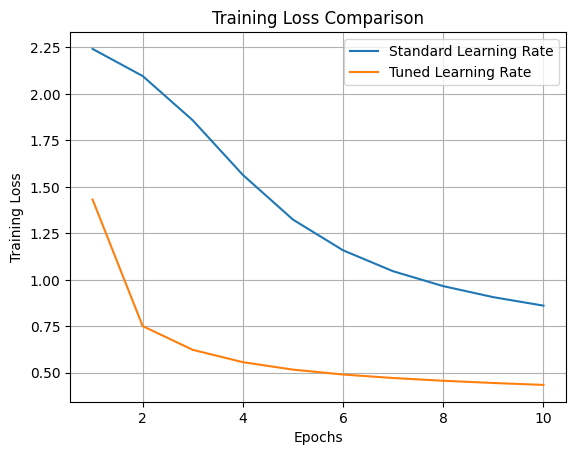

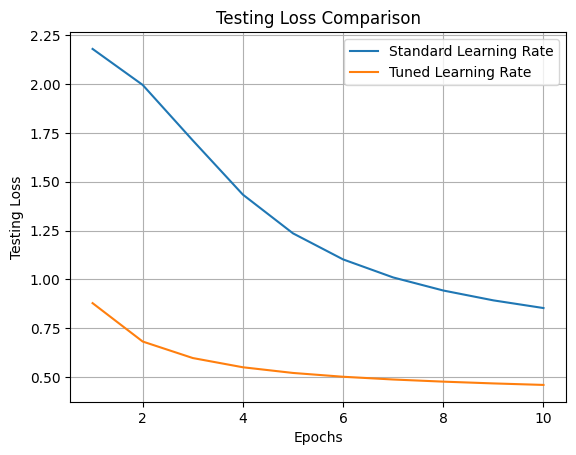

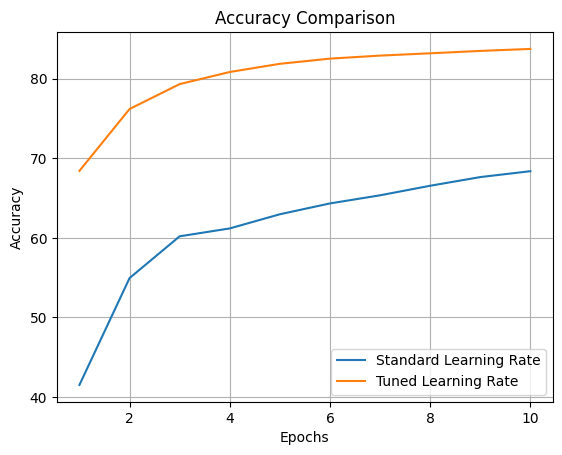

In [81]:
# Plot 1: std_train_loss_history vs tuned_lr_train_loss_history
plot_histories(
    std_train_loss_history, 
    tuned_lr_train_loss_history, 
    title='Training Loss Comparison',
    ylabel='Training Loss'
)

# Plot 2: std_test_loss_history vs tuned_lr_test_loss_history
plot_histories(
    std_test_loss_history, 
    tuned_lr_test_loss_history, 
    title='Testing Loss Comparison',
    ylabel='Testing Loss'
)

# Plot 3: std_accuracy_history vs tuned_lr_accuracy_history
plot_histories(
    std_accuracy_history, 
    tuned_lr_accuracy_history, 
    title='Accuracy Comparison',
    ylabel='Accuracy'
)
